# Лекция 9. Алгоритмы для равенств: Ньютон–Лагранж, range-space и null-space, обобщённый Гаусс–Ньютон

**Курс:** Вычислительная оптимизация · **Часть III. Ограничения-равенства** · Лекция 9 из 16 · 19 ноября 2026

**Материалы:** [конспект-ноутбук с кодом демонстраций](lecture09.ipynb) · [демо-ноутбук](demo09.ipynb) · [семинар: бросок с сопротивлением воздуха](seminar09.ipynb) · [разбор упражнений](exercises09.ipynb)

В конспекте-ноутбуке текст идёт подряд, а три демо собраны в конце: (a) к §2, (b) к §3–§4, (c) к §5.

---

> **Код в этом ноутбуке.** Текст лекции идёт подряд, без кода. Три демо из [`demo09.ipynb`](demo09.ipynb) собраны в конце, в разделе «Демо»: (a) к §2 — метод Ньютона–Лагранжа, (b) к §3–§4 — матрица ККТ и шаг по частям, (c) к §5 — обобщённый Гаусс–Ньютон. Числа введения и подробности — только в `demo09.ipynb`. Нужен CasADi: `uv run --group casadi jupyter lab`, в Colab он ставится сам.

## Введение

В лекции 8 условие решения задачи с равенствами записали системой уравнений. В простых задачах её решали руками. Сегодня — метод, которым такие системы решают солверы, и две задачи для него: «дорога» и «бросок».

### Задача 1. Дом у дороги

Дом стоит в точке $a=(2,1)$. Дорога идёт по параболе $x_2=x_1^2$. Где ближайшая к дому точка дороги?

$$
\min_{x\in\mathbb R^2}\ f(x)=\tfrac12\lVert x-a\rVert^2\qquad\text{при}\qquad g(x)=x_2-x_1^2=0 .
$$

Здесь $x=(x_1,x_2)\in\mathbb R^2$ — точка плоскости. Функция $f$ — половина квадрата расстояния от $x$ до дома.

<img src="img/00_road.png" width="640" alt="парабола x2 = x1² — дорога; справа дом в точке a = (2, 1); под дорогой стартовая точка x(0) = (1, 0)">

*Дорога, дом и старт метода $x^{(0)}=(1,0)$. Старт лежит не на дороге.*

**Система.** Условие лекции 8: $\nabla f=\lambda\nabla g$ и $g=0$. Градиенты: $\nabla f=(x_1-2,\ x_2-1)$ и $\nabla g=(-2x_1,\ 1)$. Покомпонентно:

$$
\begin{aligned}
x_1-2&=-2\lambda x_1,\\
x_2-1&=\lambda,\\
x_2-x_1^2&=0 .
\end{aligned}
$$

Первые два уравнения — градиент $f$ параллелен градиенту $g$, третье — сама дорога.

**3 уравнения на 3 неизвестных: $x_1$, $x_2$ и $\lambda$.**

Подставим $\lambda=x_2-1=x_1^2-1$ в первое уравнение. Получится кубическое уравнение $2x_1^3-x_1-2=0$. Простой формулы для его корня нет — нужен численный метод.

### Задача 2. Бросок мяча

Мяч бросают с земли так, чтобы он упал на расстоянии $D=30$ м. С какой наименьшей скоростью это можно сделать?

$$
\min_{x\in\mathbb R^3}\ f(x)=\tfrac12\big(v_1^2+v_2^2\big)\qquad\text{при}\qquad g_1(x)=v_1T-D=0,\qquad g_2(x)=v_2T-4.905\,T^2=0 .
$$

Здесь $x=(v_1,v_2,T)\in\mathbb R^3$ — вектор из трёх чисел. Числа $v_1$ и $v_2$ — горизонтальная и вертикальная скорость в момент броска, м/с. Число $T$ — время полёта, с.

Ограничения — уравнения полёта без сопротивления воздуха:

- $g_1$: за время $T$ мяч пролетает $D$ по горизонтали;
- $g_2$: через время $T$ мяч снова на земле; $4.905=9.81/2$.

<img src="img/00_throw.png" width="900" alt="четыре траектории из точки старта в цель на расстоянии 30 м: броски под углами 30°, 45°, 60° и 75°; высота полёта растёт с углом">

*Все четыре броска падают в цель, но начальные скорости у них разные.*

**Система.** Градиенты по $(v_1,v_2,T)$: $\nabla f=(v_1,\ v_2,\ 0)$, $\nabla g_1=(T,\ 0,\ v_1)$, $\nabla g_2=(0,\ T,\ v_2-9.81\,T)$. Условие $\nabla f=\lambda_1\nabla g_1+\lambda_2\nabla g_2$ покомпонентно и два ограничения:

$$
\begin{aligned}
\text{по } v_1:\quad v_1&=\lambda_1T,\\
\text{по } v_2:\quad v_2&=\lambda_2T,\\
\text{по } T:\quad 0&=\lambda_1v_1+\lambda_2\,(v_2-9.81\,T),\\
v_1T&=D,\\
v_2T&=4.905\,T^2 .
\end{aligned}
$$

**5 уравнений на 5 неизвестных: $v_1,v_2,T$ и $\lambda_1,\lambda_2$.**

**Зачем вторая задача.** Её ответ знаком из школьной физики — по нему проверим метод. Ограничений здесь два, и на этой задаче появится матрица $J$.

### Зачем это вам

Системы условий почти никогда не решают формулами. Солвер решает их итерациями, и каждая итерация — одна линейная система. Так устроены IPOPT, методы SQP (лекция 13) и солверы для управления MPC (лекция 15). Зная эту систему, вы поймёте, почему солвер сходится за 4 итерации — или не делает ни шага.

**Главная тема лекции — матрица ККТ** (матрица Каруша–Куна–Таккера). Это матрица той линейной системы, которую метод решает на каждом шаге.

**Три вопроса лекции:**

1. Как решить систему условий итерациями?
2. Когда шаг метода определён?
3. Как сделать шаг дешевле?

**План:**

- §1 — условия лекции 8 как одна система $F=0$;
- §2 — метод Ньютона–Лагранжа: задача «дорога» руками, «бросок» против IPOPT;
- §3 — когда матрица ККТ невырождена;
- §4 — шаг по частям: к ограничению и вдоль него;
- §5 — обобщённый Гаусс–Ньютон: шаг без вторых производных;
- семинар — бросок с сопротивлением воздуха.

## 1. Система, которую решаем

**Главная мысль.** В условии лекции 8 неизвестны и точка $x$, и множители $\lambda$. Перенесём все слагаемые влево — получится одна система $F=0$ с равным числом уравнений и неизвестных.

**Дорога.** Задача 1 — ближайшая к дому $a=(2,1)$ точка дороги:

$$
\min_{x\in\mathbb R^2}\ \tfrac12\lVert x-a\rVert^2\qquad\text{при}\qquad x_2-x_1^2=0 .
$$

Её система из введения:

$$
\begin{aligned}
x_1-2&=-2\lambda x_1,\\
x_2-1&=\lambda,\\
x_2-x_1^2&=0 .
\end{aligned}
$$

Перенесём правые части влево. Неизвестных три — $x_1$, $x_2$ и $\lambda$, функций тоже три:

$$
F(x_1,x_2,\lambda)=\begin{pmatrix}x_1-2+2\lambda x_1\\ x_2-1-\lambda\\ x_2-x_1^2\end{pmatrix}=0 .
$$

Первые две строки — это $\nabla f-\lambda\nabla g$. Они требуют, чтобы отрезок от дома до точки $x$ был перпендикулярен дороге: $x-a$ параллелен нормали $\nabla g=(-2x_1,\ 1)$. Третья строка — сама дорога.

**Бросок.** Задача 2 — бросок на $D=30$ м с наименьшей скоростью, $x=(v_1,v_2,T)\in\mathbb R^3$:

$$
\min_{x\in\mathbb R^3}\ \tfrac12\big(v_1^2+v_2^2\big)\qquad\text{при}\qquad g_1=v_1T-D=0,\qquad g_2=v_2T-4.905\,T^2=0 .
$$

Её система из введения — три уравнения касания и два ограничения:

$$
\begin{aligned}
v_1&=\lambda_1T, & v_1T&=D,\\
v_2&=\lambda_2T, & v_2T&=4.905\,T^2,\\
0&=\lambda_1v_1+\lambda_2\,(v_2-9.81\,T) .
\end{aligned}
$$

Здесь два ограничения и два множителя. Градиенты: $\nabla f=(v_1,\ v_2,\ 0)$, $\nabla g_1=(T,\ 0,\ v_1)$ и $\nabla g_2=(0,\ T,\ v_2-9.81\,T)$. Три уравнения касания — это покомпонентно одно векторное равенство:

$$
\nabla f=\lambda_1\nabla g_1+\lambda_2\nabla g_2 .
$$

Сумму справа удобно записать матрицей. Соберём градиенты ограничений строками — получится **якобиан ограничений** $J$ размера $2\times3$. Тогда сумма справа — это $J^\top\lambda$:

$$
J=\begin{pmatrix}T&0&v_1\\0&T&v_2-9.81\,T\end{pmatrix},\qquad
J^\top\lambda=\lambda_1\begin{pmatrix}T\\0\\v_1\end{pmatrix}+\lambda_2\begin{pmatrix}0\\T\\v_2-9.81\,T\end{pmatrix}.
$$

Перенесём всё влево и добавим ограничения. Получится пять функций пяти неизвестных $v_1,v_2,T,\lambda_1,\lambda_2$:

$$
F=\begin{pmatrix}\nabla f-J^\top\lambda\\ g\end{pmatrix}=\begin{pmatrix}v_1-\lambda_1T\\ v_2-\lambda_2T\\ -\lambda_1v_1-\lambda_2\,(v_2-9.81\,T)\\ v_1T-D\\ v_2T-4.905\,T^2\end{pmatrix}=0 .
$$

**Общий случай.** Пусть $x\in\mathbb R^n$, а ограничений $m$. Строки якобиана $J$ — градиенты $\nabla g_1,\dots,\nabla g_m$. Условие лекции 8 — $\nabla f=J^\top\lambda$, и система такая:

$$
F(x,\lambda)=\begin{pmatrix}\nabla f(x)-J(x)^\top\lambda\\ g(x)\end{pmatrix}=0 .
$$

*Размеры:* $\lambda\in\mathbb R^m$; $J$ — $m\times n$; $F$ — вектор из $n+m$ чисел, неизвестных тоже $n+m$.

Верхняя половина $F$ — градиент функции Лагранжа $L=f-\lambda^\top g$ по $x$. Его пишут $\nabla_xL$.

## 2. Метод Ньютона–Лагранжа

**Главная мысль.** Это метод Ньютона для системы $F(x,\lambda)=0$: точку $x$ и множители $\lambda$ он ищет вместе. На каждом шаге решается одна линейная система. Её матрица — матрица Якоби системы $F$, её называют матрицей ККТ.

Вспомним лекцию 5, §2.1. Пусть $z$ — вектор всех неизвестных, а $F(z)=0$ — система, где уравнений столько же, сколько неизвестных. Метод Ньютона в текущей точке заменяет $F$ линейной моделью и приравнивает её к нулю:

$$
F\big(z^{(k)}\big)+J_F\big(z^{(k)}\big)\,s=0,\qquad z^{(k+1)}=z^{(k)}+s .
$$

*Размеры:* у нас $z=(x,\lambda)$ и $s$ — векторы из $n+m$ чисел; $J_F$ — матрица Якоби системы $F$, размер $(n+m)\times(n+m)$. Верхний индекс $(k)$ — номер итерации, нижний — номер координаты.

Если $J_F$ в решении невырождена, а старт близок к решению, сходимость квадратичная (лекция 5, §3.1). Чтобы делать шаги, нужна матрица $J_F$ — выпишем её.

### 2.1. Матрица Якоби

**Определение.** Матрица Якоби $J_F$ — таблица частных производных системы $F$. В строке $i$ стоят производные функции $F_i$ по всем неизвестным по очереди:

$$
\big(J_F\big)_{ij}=\frac{\partial F_i}{\partial z_j}.
$$

**Дорога.** Неизвестные — $z=(x_1,x_2,\lambda)$, система

$$
F=\begin{pmatrix}x_1-2+2\lambda x_1\\ x_2-1-\lambda\\ x_2-x_1^2\end{pmatrix}.
$$

Продифференцируем каждую строку по $x_1$, $x_2$ и $\lambda$:

$$
J_F=\begin{pmatrix}1+2\lambda&0&2x_1\\0&1&-1\\-2x_1&1&0\end{pmatrix}.
$$

Например, первая строка $x_1-2+2\lambda x_1$ даёт $1+2\lambda$ по $x_1$, ноль по $x_2$ и $2x_1$ по $\lambda$.

**Бросок.** Неизвестные — $z=(v_1,v_2,T,\lambda_1,\lambda_2)$, система

$$
F=\begin{pmatrix}v_1-\lambda_1T\\ v_2-\lambda_2T\\ -\lambda_1v_1-\lambda_2\,(v_2-9.81\,T)\\ v_1T-D\\ v_2T-4.905\,T^2\end{pmatrix}.
$$

Продифференцируем каждую строку по $v_1$, $v_2$, $T$, $\lambda_1$ и $\lambda_2$:

$$
J_F=\begin{pmatrix}1&0&-\lambda_1&-T&0\\0&1&-\lambda_2&0&-T\\-\lambda_1&-\lambda_2&9.81\,\lambda_2&-v_1&-(v_2-9.81\,T)\\T&0&v_1&0&0\\0&T&v_2-9.81\,T&0&0\end{pmatrix}.
$$

Например, третья строка $-\lambda_1v_1-\lambda_2v_2+9.81\,\lambda_2T$ даёт $9.81\,\lambda_2$ по $T$ и $-(v_2-9.81\,T)$ по $\lambda_2$.

**Общий случай.** У обеих матриц одно устройство. Чтобы увидеть, откуда оно, продифференцируем систему в общем виде:

$$
F(x,\lambda)=\begin{pmatrix}\nabla f(x)-\lambda_1\nabla g_1(x)-\dots-\lambda_m\nabla g_m(x)\\ g(x)\end{pmatrix}.
$$

Верхняя половина — $n$ строк касания, нижняя — $m$ ограничений. Столбцов тоже две группы: производные по $x$ и по $\lambda$. Получается четыре блока:

- **верхняя половина по $x$.** Производная $\nabla f$ — гессиан $\nabla^2f$, производная $\lambda_j\nabla g_j$ — $\lambda_j\nabla^2g_j$. Блок — гессиан функции Лагранжа по $x$:

$$
H=\nabla^2f-\sum_{j=1}^m\lambda_j\nabla^2g_j ;
$$

- **верхняя половина по $\lambda_j$.** От $\lambda_j$ зависит только слагаемое $-\lambda_j\nabla g_j$, его производная — $-\nabla g_j$. Все $m$ таких столбцов вместе — $-J^\top$;
- **нижняя половина по $x$** — производные ограничений, то есть якобиан ограничений $J$;
- **нижняя половина по $\lambda$** — ноль: ограничения от $\lambda$ не зависят.

Итог — **матрица ККТ** (*KKT matrix*):

$$
K=J_F=\begin{pmatrix}H&-J^\top\\ J&0\end{pmatrix}.
$$

*Размеры:* $K$ — $(n+m)\times(n+m)$; $H$ — $n\times n$; $J$ — $m\times n$; нулевой блок — $m\times m$.

Проверим на примере задачи «дорога». Там $\nabla^2f=I$ и $\nabla^2g=\operatorname{diag}(-2,\ 0)$, поэтому $H=\operatorname{diag}(1+2\lambda,\ 1)$. Якобиан ограничения $J=(-2x_1,\ 1)$, столбец $-J^\top=(2x_1,\ -1)$. Это ровно блоки её матрицы Якоби выше. В задаче «бросок» $H$ — левый верхний угол $3\times3$, а $J$ — две нижние строки.

### 2.2. Алгоритм Ньютона–Лагранжа

**Алгоритм** (*Newton–Lagrange method*):

1. Выбрать старт: $x^{(0)}\in\mathbb R^n$ и $\lambda^{(0)}\in\mathbb R^m$.
2. Посчитать в текущей точке $\nabla f$ ($n$ чисел), $g$ ($m$ чисел), $J$ ($m\times n$) и $H$ ($n\times n$).
3. Решить систему $K\,(p,\Delta\lambda)=-F$, где $p\in\mathbb R^n$ и $\Delta\lambda\in\mathbb R^m$.
4. Сделать шаг: $x^{(k+1)}=x^{(k)}+p$ и $\lambda^{(k+1)}=\lambda^{(k)}+\Delta\lambda$.
5. Повторять пункты 2–4, пока $\lVert F\rVert$ больше допуска.

**Чем он отличается от метода Ньютона лекции 5:**

- неизвестных $n+m$: метод ищет точку и множители вместе;
- нужен старт и для множителей;
- промежуточные точки нарушают ограничения, $g=0$ выполняется только в пределе.

### 2.3. Дом у дороги руками

**Шаг из $x^{(0)}=(1,0)$ при $\lambda^{(0)}=0$.** Подставим $x_1=1$, $x_2=0$, $\lambda=0$ в систему задачи «дорога» и её матрицу Якоби:

$$
F=\begin{pmatrix}1-2+0\\ 0-1-0\\ 0-1\end{pmatrix}=\begin{pmatrix}-1\\-1\\-1\end{pmatrix},\qquad
K=\begin{pmatrix}1&0&2\\0&1&-1\\-2&1&0\end{pmatrix}.
$$

Неизвестные шага — $p=(p_1,p_2)$ и $\Delta\lambda$. Система $K\,(p,\Delta\lambda)=-F$:

$$
\begin{pmatrix}1&0&2\\0&1&-1\\-2&1&0\end{pmatrix}\begin{pmatrix}p_1\\p_2\\\Delta\lambda\end{pmatrix}=\begin{pmatrix}1\\1\\1\end{pmatrix}.
$$

Из первых двух строк $p_1=1-2\Delta\lambda$ и $p_2=1+\Delta\lambda$. Третья строка даёт $-2+5\Delta\lambda=0$. Отсюда $\Delta\lambda=0.4$ и $p=(0.2,\ 1.4)$.

**Итерации.**

$$
x^{(1)}=(1.2,\ 1.4),\qquad\lambda^{(1)}=0.4 .
$$

**Почему $x^{(1)}$ не на дороге.** Проверим: $1.2^2=1.44\ne1.4$. Третья строка системы шага — $-2p_1+p_2=1$. Это ограничение, линеаризованное в старте. Для точки $x=x^{(0)}+p$ оно задаёт прямую $x_2=2x_1-1$ — касательную к дороге в точке $(1,1)$. Шаг кончается на этой прямой, а дорога загибается вверх.

**Это не ошибка метода.** На каждой итерации ограничение линеаризуется заново, в новой точке. Поэтому точки подходят к дороге. Нарушение $x_2-x_1^2$ по итерациям: $-1$, $-0.04$, $-0.0011$, $-6\cdot10^{-7}$, $-10^{-13}$. Норма невязки $\lVert F\rVert$: $1.73$, $0.165$, $0.0030$, $1.1\cdot10^{-6}$, $1.6\cdot10^{-13}$.

За 4 итерации метод нашёл $x^\ast=(1.165,\ 1.358)$ и $\lambda^\ast=0.358$. Ответ лежит на дороге: нарушение в нём $10^{-13}$. Расстояние от дома до дороги — $0.908$.

<img src="img/01_nl_road.png" width="900" alt="слева: дорога-парабола, дом a = (2, 1), итерации из x(0) = (1, 0): первый шаг идёт до пунктирной касательной x2 = 2x1 − 1 и кончается в точке (1.2, 1.4) рядом с дорогой и ответом x* = (1.165, 1.358); справа: норма невязки по итерациям в логарифмической шкале — 1.73, 0.16, 0.003, 1.1·10⁻⁶, 1.6·10⁻¹³">

*Слева: первый шаг кончается на касательной $x_2=2x_1-1$, рядом с дорогой. Следующие точки ложатся на дорогу. Справа: число верных цифр удваивается — сходимость квадратичная.*

### 2.4. Бросок и IPOPT

Решим задачу 2 тем же алгоритмом. Матрица ККТ — $5\times5$, её значения в каждой точке даёт CasADi (лекция 7).

Старт — $v=(10,\ 10)$ м/с и $T=2$ с. Такой мяч к моменту $T$ пролетает лишь 20 м.

**Стартовые множители.** В задаче «дорога» мы взяли $\lambda^{(0)}=0$. Солверы поступают иначе: берут $\lambda^{(0)}$, при котором условие касания $\nabla f=J^\top\lambda$ в старте выполнено как можно точнее. Это задача наименьших квадратов (МНК):

$$
\lambda^{(0)}=\big(JJ^\top\big)^{-1}J\,\nabla f .
$$

*Размеры:* $JJ^\top$ — $m\times m$, $\lambda^{(0)}\in\mathbb R^m$. В задаче «бросок» в старте $\lambda^{(0)}=(4.903,\ 5.093)$.

**Итерации.** Норма невязки по итерациям:

$$
10.0\ \to\ 1.47\ \to\ 0.026\ \to\ 6.9\cdot10^{-6}\ \to\ 1.8\cdot10^{-13}.
$$

Ответ — бросок под $45^\circ$: $v_1=v_2=12.13$ м/с, скорость $17.16$ м/с, $T=2.47$ с. Множители $\lambda^\ast=(4.905,\ 4.905)$. С $\lambda^{(0)}=0$ метод тоже сходится, но за 5 итераций.

**Сверка с IPOPT.** IPOPT решает ту же задачу из того же старта за 4 итерации. В логе он печатает две половины невязки отдельно. Колонка `inf_pr` — наибольшее $\lvert g_j\rvert$, колонка `inf_du` — наибольшая по модулю компонента $\nabla_xL$.

<img src="img/02_nl_throw.png" width="900" alt="слева: полёт мяча до момента T на итерациях 0, 1, 2 и 4; на итерации 0 мяч к моменту T пролетает 20 м, дальше конец полёта приходит в цель на 30 м; справа: две половины невязки нашего метода по итерациям (линии) и значения из лога IPOPT (крестики) — крестики лежат на линиях">

*Слева: к моменту $T$ мяч сначала не долетает, потом конец полёта приходит в цель. Справа: крестики лога IPOPT лежат на линиях нашего метода.*

Числа совпали до 8 значащих цифр. На этой задаче IPOPT делает ровно шаги Ньютона–Лагранжа. Код — демо (a).

## 3. Матрица ККТ

**Главная мысль.** Шаг определён, когда матрица ККТ невырождена. Для этого хватает двух условий лекции 8: LICQ и положительного редуцированного гессиана. Тогда метод сходится квадратично.

### 3.1. Три понятия лекции 8

Теорема этого раздела опирается на три понятия лекции 8. Вспомним каждое на примере задачи «дорога»:

$$
\min_{x\in\mathbb R^2}\ \tfrac12\lVert x-a\rVert^2\qquad\text{при}\qquad g(x)=x_2-x_1^2=0,\qquad a=(2,1).
$$

Здесь $n=2$ неизвестных и $m=1$ ограничение.

**1. Якобиан ограничений и LICQ.** Якобиан $J$ — матрица $m\times n$, её строка $j$ — градиент ограничения $g_j$. LICQ (*linear independence constraint qualification*) — условие, что строки $J$ линейно независимы. Зачем это условие: при LICQ у минимума есть множители $\lambda$, и система $F=0$ решения не теряет.

В задаче «дорога» строка одна — градиент ограничения: $J=\nabla g^\top=(-2x_1,\ 1)$. Один вектор линейно независим, если он ненулевой. Эта строка не равна нулю ни в одной точке: её вторая компонента всегда $1$. Значит, LICQ выполнено везде, и у дороги в каждой точке есть нормаль $\nabla g$. В задаче «бросок» строк две, и при $T=0$ они совпадают — там LICQ нарушено.

**2. Касательное пространство и матрица $Z$.** Касательное пространство — векторы $p\in\mathbb R^n$ с $Jp=0$: сдвиг вдоль них в первом порядке не меняет ограничений. Его размерность $n-m$. Столбцы матрицы $Z$ размера $n\times(n-m)$ — его базис. Значит, $JZ=0$, и любой касательный вектор равен $Zu$, где $u\in\mathbb R^{n-m}$. В задаче «дорога» $n-m=1$:

$$
-2x_1p_1+p_2=0\qquad\Longrightarrow\qquad p=p_1\,(1,\ 2x_1).
$$

$Z$ — один столбец вдоль касательной к параболе: её наклон в точке $x_1$ равен $2x_1$. В старте $(1,0)$ нормированный столбец — $Z=(1,\ 2)/\sqrt5$.

**3. Гессиан функции Лагранжа и редуцированный гессиан.** Гессиан функции Лагранжа $L=f-\lambda^\top g$ по $x$ — матрица $n\times n$ в левом верхнем блоке $K$:

$$
H=\nabla^2f-\sum_{j=1}^m\lambda_j\nabla^2g_j .
$$

Редуцированный гессиан $Z^\top HZ$ размера $(n-m)\times(n-m)$ — кривизна $H$ только вдоль касательного пространства: при $p=Zu$ выполнено $p^\top Hp=u^\top\big(Z^\top HZ\big)u$. В задаче «дорога» $\nabla^2f=I$ и $\nabla^2g=\operatorname{diag}(-2,\ 0)$, поэтому $H=\operatorname{diag}(1+2\lambda,\ 1)$. В старте при $\lambda=0$ получаем $H=I$ и $Z^\top HZ=1$. Двигаться можно только вдоль ограничения, поэтому важна только эта кривизна. Если в решении $Z^\top HZ\succ0$, это строгий локальный минимум (лекция 8).

### 3.2. Теорема

**Зачем теорема.** На каждой итерации метод решает линейную систему $K\,(p,\Delta\lambda)=-F$. Если $K$ вырождена, у этой системы нет единственного решения, и шага нет. Так бывает: в задаче «бросок» при $T=0$ NumPy выдаёт `Singular matrix`. Теорема говорит, при каких свойствах задачи этого не случится.

**Теорема.** Пусть в точке $(x,\lambda)$ строки $J$ линейно независимы, а $Z^\top HZ\succ0$ (положительно определена). Тогда матрица ККТ $K$ невырождена.

**Что из неё следует.**

- **В решении** условия теоремы — это LICQ и достаточное условие второго порядка лекции 8, то есть условия строгого минимума. Значит, рядом с таким минимумом $K$ обратима. По теореме лекции 5 метод сходится квадратично — 4 итерации в обеих задачах лекции.
- **Если шага нет**, нарушено одно из двух условий. Нет LICQ — меняют старт или запись ограничений. Нет кривизны вдоль ограничения — IPOPT прибавляет к $H$ матрицу $\delta I$.

**Доказательство.** Пусть $K\,(p,\mu)=0$ для некоторых $p\in\mathbb R^n$ и $\mu\in\mathbb R^m$. Покомпонентно это два уравнения:

$$
Hp-J^\top\mu=0,\qquad Jp=0 .
$$

**Шаг 1. Вектор $p$ касательный.** Из второго уравнения $Jp=0$, поэтому $p=Zu$ для некоторого $u\in\mathbb R^{n-m}$.

**Шаг 2. $p=0$.** Умножим первое уравнение на $p^\top$ слева: $p^\top Hp=(Jp)^\top\mu=0$. Подставим $p=Zu$ и получим $u^\top\big(Z^\top HZ\big)u=0$. Матрица $Z^\top HZ$ положительно определена, поэтому $u=0$ и $p=0$.

**Шаг 3. $\mu=0$.** При $p=0$ первое уравнение даёт $J^\top\mu=0$ — нулевую комбинацию строк $J$. Строки независимы, поэтому $\mu=0$. $\blacksquare$

### 3.3. Бросок, который ещё не начался

**Если в старте нарушено LICQ, шаг не определён.** В задаче «бросок» так бывает при $T=0$ — мяч ещё в руке. Возьмём старт $v=(10,\ 10)$, $T=0$:

$$
J=\begin{pmatrix}T&0&v_1\\0&T&v_2-9.81\,T\end{pmatrix}=\begin{pmatrix}0&0&10\\0&0&10\end{pmatrix},\qquad g=\begin{pmatrix}-30\\0\end{pmatrix}.
$$

Строки $J$ совпадают — LICQ нарушено, и шаг 3 доказательства не проходит. Линеаризованные ограничения $g+Jp=0$ требуют $10\,p_T=30$ и $10\,p_T=0$, где $p_T$ — изменение времени полёта. Шага нет: NumPy сообщает, что $K$ вырождена (`Singular matrix`). При $T=0$ оба ограничения меняются только через $T$, и сдвинуть их независимо нельзя. Поэтому старт берут с $T>0$.

### 3.4. Вопрос залу

Пусть дом стоит над вершиной дороги, в точке $(0,\ 2)$. Метод стартует в самой вершине $(0,0)$ при $\lambda^{(0)}=0$. Куда он придёт?

<img src="img/03_road_vertex.png" width="640" alt="дорога-парабола, дом в точке (0, 2) над вершиной; метод из вершины остаётся в вершине с λ = −2; две ближайшие к дому точки ±(1.22, 1.5) с λ = −0.5 лежат на пунктирной окружности радиуса 1.32 вокруг дома, а вершина — дальше, на расстоянии 2">

*Метод остаётся в вершине за одну итерацию: меняется только $\lambda$, до $-2$. Ближайшие точки — $\pm(1.22,\ 1.5)$.*

Ответ: вершина — тоже решение системы. Для дома $a=(0,2)$ система такая:

$$
x_1=-2\lambda x_1,\qquad x_2-2=\lambda,\qquad x_2=x_1^2 .
$$

При $x=(0,0)$ и $\lambda=-2$ все три уравнения выполнены. Но в вершине $Z=(1,\ 0)$ и $Z^\top HZ=1+2\lambda=-3<0$: при сдвиге вдоль дороги расстояние уменьшается. До вершины $2$, до ближайших точек $1.32$.

**Чего теорема не обещает:** что метод придёт в минимум. В максимуме $Z^\top HZ\prec0$, и $K$ тоже невырождена — доказательство то же, со сменой знака. Метод ищет решение системы, а минимум проверяют условием второго порядка (лекция 8, §4).

## 4. Шаг по частям

**Главная мысль.** Шаг Ньютона–Лагранжа состоит из двух частей. Первая ведёт на линеаризованное ограничение, вторая идёт вдоль него. Вторая часть решает систему размера $n-m$ с матрицей $Z^\top HZ$.

Перепишем систему шага через новые множители $\lambda^+=\lambda+\Delta\lambda$. Слагаемое $J^\top\lambda$ из $F$ сократится:

$$
Hp-J^\top\lambda^+=-\nabla f,\qquad Jp=-g .
$$

*Размеры:* $p\in\mathbb R^n$, $\lambda^+\in\mathbb R^m$.

Второе уравнение — ограничение, линеаризованное в текущей точке: $g+Jp=0$. Шаг кончается на нём, а не на самом ограничении.

Разберём первый шаг в задаче «дорога» — из $x^{(0)}=(1,0)$ при $\lambda=0$ в $x^{(1)}=(1.2,\ 1.4)$. В старте $H=I$, $\nabla f=(-1,\ -1)$, $J=(-2,\ 1)$, $g=-1$. Линеаризованная дорога $-1-2p_1+p_2=0$ — это прямая $x_2=2x_1-1$, касательная к дороге в точке $(1,1)$.

**Часть к ограничению.** Самый короткий вектор $p_N$ с $Jp_N=-g$ перпендикулярен прямой, то есть идёт вдоль строки $J$:

$$
p_N=-J^\top\big(JJ^\top\big)^{-1}g .
$$

*Размеры:* $JJ^\top$ — $m\times m$, $p_N\in\mathbb R^n$. В задаче «дорога» $JJ^\top=5$, и $p_N=(-2,\ 1)/5=(-0.4,\ 0.2)$. Точка $(0.6,\ 0.2)$ лежит на прямой.

**Часть вдоль ограничения.** Ищем шаг в виде $p=p_N+Zu$, где $u\in\mathbb R^{n-m}$. Подставим его в первое уравнение и умножим слева на $Z^\top$. Слагаемое с $\lambda^+$ пропадёт, потому что $Z^\top J^\top=(JZ)^\top=0$:

$$
Z^\top HZ\,u=-Z^\top\big(\nabla f+Hp_N\big).
$$

*Размеры:* $Z^\top HZ$ — $(n-m)\times(n-m)$, $u\in\mathbb R^{n-m}$.

В задаче «дорога» $Z=(1,\ 2)/\sqrt5$ и $\nabla f+Hp_N=(-1.4,\ -0.8)$. Отсюда $u=3/\sqrt5$ и $Zu=(0.6,\ 1.2)$. Сумма $p_N+Zu=(0.2,\ 1.4)$ — ровно шаг, который дала полная система.

<img src="img/04_step_split.png" width="680" alt="дорога-парабола, дом a, старт x(0) = (1, 0), пунктирная прямая x2 = 2x1 − 1 — дорога, линеаризованная в x(0); оранжевая стрелка p_N = (−0.4, 0.2) ведёт на прямую, синяя Zu = (0.6, 1.2) идёт вдоль неё в x(1) = (1.2, 1.4); точечная стрелка — весь шаг">

*Оранжевая часть ведёт на прямую $x_2=2x_1-1$, синяя идёт вдоль неё. Дорога загибается вверх, и шаг кончается рядом с ней, а не на ней.*

Вот почему в теореме о матрице ККТ нужен только $Z^\top HZ$: остальная часть $H$ на шаг вдоль ограничения не влияет.

**Множители** находят после шага из первого уравнения: $J^\top\lambda^+=Hp+\nabla f$. В задаче «дорога» $Hp+\nabla f=(-0.8,\ 0.4)=0.4\cdot(-2,\ 1)$, поэтому $\lambda^+=0.4$ — тот же $\lambda^{(1)}$, что дала полная система.

**Range-space — тот же шаг в другом порядке.** Если $H$ обратима, выразим $p=H^{-1}\big(J^\top\lambda^+-\nabla f\big)$ из первого уравнения. Подставим во второе и получим систему $m\times m$ на множители:

$$
JH^{-1}J^\top\lambda^+=JH^{-1}\nabla f-g .
$$

В задаче «дорога» это $5\lambda^+=2$, и снова $\lambda^+=0.4$.

Названия методов — от двух подпространств. *Null space* — ядро $J$, там лежит $Zu$. *Range space* — комбинации строк $J$, там лежит $p_N$.

| Способ | Размер системы | Дорога | Бросок |
|---|---|---|---|
| вся матрица $K$ | $(n+m)\times(n+m)$ | $3\times3$ | $5\times5$ |
| null-space | $(n-m)\times(n-m)$ | $1\times1$ | $1\times1$ |
| range-space | $m\times m$ | $1\times1$ | $2\times2$ |

Null-space нужен базис $Z$, range-space — обратимая $H$. IPOPT и другие солверы общего назначения раскладывают всю $K$: она большая, но почти вся из нулей. Null-space выгоден, когда $n-m$ мало. Range-space — когда $H$ легко обратить, как в задачах управления (лекция 15).

## 5. Обобщённый Гаусс–Ньютон

**Главная мысль.** Если $f$ — сумма квадратов невязок, в матрицу ККТ вместо $H$ ставят $J_r^\top J_r$. Вторые производные и множители для матрицы не нужны. Плата — линейная сходимость: ошибка за шаг умножается на число $q$, и оно мало, когда мал $\lambda^\ast$.

Вспомним лекцию 5, §5.2. Пусть $f(x)=\tfrac12\lVert r(x)\rVert^2$, где $r(x)$ — вектор невязок. Его якобиан $J_r$ — матрица, у которой строк столько, сколько невязок, и $n$ столбцов. Метод Гаусса–Ньютона заменяет $\nabla^2f$ на $J_r^\top J_r$.

С ограничениями то же самое делают в системе шага $Hp-J^\top\lambda^+=-\nabla f$, $Jp=-g$: вместо $H$ ставят $J_r^\top J_r$.

$$
\begin{pmatrix}J_r^\top J_r&-J^\top\\ J&0\end{pmatrix}\begin{pmatrix}p\\ \lambda^+\end{pmatrix}=\begin{pmatrix}-J_r^\top r\\ -g\end{pmatrix}.
$$

*Размеры:* $J_r^\top J_r$ — $n\times n$; остальные блоки — как в матрице ККТ. Справа стоит $\nabla f=J_r^\top r$.

Это **обобщённый метод Гаусса–Ньютона** (*constrained Gauss–Newton*). По сравнению с $H$ в матрице нет двух слагаемых:

- вторых производных невязок — как в лекции 5;
- кривизны ограничений $-\sum_j\lambda_j\nabla^2g_j$.

Поэтому $\lambda$ в матрицу не входит.

**Дорога.** Расстояние до дома — сумма квадратов: $r=x-a$, $J_r=I$. В матрице стоит $I$ вместо точного $H=\operatorname{diag}(1+2\lambda,\ 1)$. Выброшено слагаемое $\operatorname{diag}(2\lambda,\ 0)$ — кривизна дороги, умноженная на $\lambda$.

При $\lambda=0$ обе матрицы равны $I$, поэтому первый шаг из $(1,0)$ у методов общий — в $(1.2,\ 1.4)$. Это проекция дома на касательную $x_2=2x_1-1$ (картинка шага по частям). Дальше шаги расходятся.

**Скорость.** Пусть $n-m=1$, как в задаче «дорога». Шаг раскладывается как $p=p_N+Zu$, и $u$ — одно число: сдвиг вдоль дороги. Уравнение для него, $Z^\top HZ\,u=-Z^\top(\nabla f+Hp_N)$, — шаг Ньютона по одной переменной. Справа наклон $f$ вдоль дороги, слева её вторая производная $Z^\top HZ$.

Гаусс–Ньютон ставит слева $Z^\top Z$ вместо $Z^\top HZ$. Вблизи ответа наклон равен $Z^\top HZ\cdot e_k$, где $e_k$ — ошибка вдоль дороги. Поэтому

$$
e_{k+1}\approx e_k-\frac{Z^\top HZ}{Z^\top Z}\,e_k=q\,e_k,\qquad q=1-\frac{Z^\top HZ}{Z^\top Z}.
$$

В задаче «дорога» с вектором вдоль дороги $\tilde Z=(1,\ 2x_1)$ получаем

$$
q=1-\frac{1+2\lambda^\ast+4x_1^{\ast2}}{1+4x_1^{\ast2}}=-\frac{2\lambda^\ast}{1+4x_1^{\ast2}} .
$$

Для дома $(2,1)$ это $q=-0.111$. По модулю $q$ равно расстоянию до дороги, делённому на радиус кривизны дороги в $x^\ast$. Чем дальше дом от дороги, тем медленнее метод.

Число итераций из $x^{(0)}=(1,0)$, пока $\lVert F\rVert$ не станет меньше $10^{-10}$:

| Дом | $q$ | Гаусс–Ньютон | Ньютон–Лагранж |
|---|---|---|---|
| $(1.5,\ 2)$ | $-0.006$ | $6$ | $4$ |
| $(2,\ 1)$ | $-0.111$ | $11$ | $4$ |
| $(0,\ 0.3)$ | $0.6$ | $43$ | $6$ |

<img src="img/05_ggn_road.png" width="900" alt="слева: дом (0, 0.3) над вершиной дороги; шаги Гаусса–Ньютона медленно подходят к вершине, 43 итерации, шаги Ньютона–Лагранжа — за 6; справа: ошибка Гаусса–Ньютона по итерациям для трёх домов — прямые в логарифмической шкале, тем положе, чем больше |q|">

*Слева: к вершине Гаусс–Ньютон подходит медленно. Справа: ошибка падает по прямой — сходимость линейная, наклон задаёт $q$.*

У дома $(0,\ h)$ над вершиной ответ — вершина, $\lambda^\ast=-h$ и $q=2h$. Радиус кривизны дороги в вершине — $0.5$. Чем ближе $h$ к $0.5$, тем ближе $q$ к единице.

<img src="img/06_ggn_height.gif" width="768" alt="анимация: дом поднимается над вершиной дороги, h от 0.05 до 0.48; слева 12 шагов метода, справа ошибка по итерациям; в заголовке множитель ошибки 2h и число итераций — от 12 до 439">

*Дом поднимается над вершиной. Множитель ошибки $2h$ растёт, и при $h=0.48$ нужно уже 439 итераций.*

**В общем случае** то же: $q$ пропорционально $\lambda^\ast$. В ответе $\nabla f=J_r^\top r$ и $\nabla f=J^\top\lambda^\ast$, поэтому малые невязки дают малые множители. В задаче «бросок» невязка — сама скорость, $17$ м/с, и $\lambda^\ast=4.905$ велико. Там обобщённый Гаусс–Ньютон не сходится вовсе (демо (c)).

**Где это используют.** В acados — солвере для управления MPC (лекция 15) — опция `hessian_approx='GAUSS_NEWTON'` включает именно этот метод. Цель в MPC — сумма квадратов отклонений от заданной траектории, и невязки в ответе малы.

## 6. Что это даёт численно

**Главная мысль.** IPOPT на задаче с равенствами делает шаги Ньютона–Лагранжа и добавляет к ним три вещи.

- Стартовые множители по МНК — как в задаче «бросок».
- Если $Z^\top HZ$ не положительно определена, IPOPT прибавляет к $H$ матрицу $\delta I$. Её размер виден в поле `regularization_size` статистики итераций (семинар лекции 6).
- Издалека полный шаг может увести в максимум, как в вершину дороги для дома над ней. IPOPT укорачивает шаг линейным поиском — лекция 13.

**В ДЗ 5** вы напишете метод Ньютона–Лагранжа и обобщённый Гаусс–Ньютон и проверите их на руке робота.

## 7. Итоги лекции

1. Условие лекции 8 — система $F(x,\lambda)=0$ из $n+m$ уравнений. Метод Ньютона–Лагранжа — метод Ньютона для неё; на шаге одна система с матрицей ККТ (§1–§2).
2. Матрица ККТ невырождена при LICQ и $Z^\top HZ\succ0$, и тогда сходимость квадратичная. Метод ищет решение системы и может прийти в максимум (§3).
3. Шаг состоит из части к линеаризованному ограничению и части вдоль него. Вторая часть решает систему $(n-m)\times(n-m)$ с $Z^\top HZ$ (§4).
4. Обобщённый Гаусс–Ньютон ставит $J_r^\top J_r$ вместо $H$. Он сходится линейно, ошибка за шаг умножается на $q$, пропорциональное $\lambda^\ast$ (§5).

**Ответы на задачи введения.**

- **Задача 1.** Ближайшая точка дороги — $(1.165,\ 1.358)$, расстояние $0.908$. Метод Ньютона–Лагранжа — 4 итерации, обобщённый Гаусс–Ньютон — 11.
- **Задача 2.** Бросок под $45^\circ$ со скоростью $17.16$ м/с. Метод Ньютона–Лагранжа — 4 итерации, ровно как IPOPT. Со старта $T=0$ шаг не определён.

## 8. Что дальше

**Лекция 10** — неравенства: условия ККТ и двойственность Лагранжа. **Лекция 13** — SQP: шаг Ньютона–Лагранжа как квадратичная задача (упражнение 9.1) и линейный поиск.

**ДЗ 5** (Ньютон–Лагранж и обобщённый Гаусс–Ньютон) выдаётся 19.11, срок — 03.12.

**Литература к лекции.**

- Diehl, *Lecture Notes on Numerical Optimization*, часть III — алгоритмы для задач с равенствами: метод Ньютона–Лагранжа, обобщённый Гаусс–Ньютон.
- Nocedal & Wright: §16.1 — система ККТ и теорема о её невырожденности (лемма 16.1); §16.2 — range-space и null-space; §18.1 — метод Ньютона для условий Лагранжа.
- Boyd & Vandenberghe: §10.2–10.3 — метод Ньютона с равенствами, в том числе из недопустимого старта; §10.4 — как решать систему ККТ.

## 9. Семинар: бросок с сопротивлением воздуха

Весь семинар — за ноутбуком [`seminar09.ipynb`](seminar09.ipynb), около 30 минут. Нужен пакет CasADi: `uv sync --group casadi`; в Colab первая ячейка ставит его сама.

Продолжаем задачу 2. С сопротивлением воздуха формул для $g_1$ и $g_2$ нет: положение мяча в момент $T$ считает программа. Метод Ньютона–Лагранжа решает и такую задачу — ему нужны только значения и производные.

| Мин | Шаг |
|---|---|
| 6 | **1. Без воздуха руками.** Пять уравнений системы, ответ — $45^\circ$ |
| 6 | **2. Полёт программой.** Метод Рунге–Кутты; без воздуха — формула $s_1=v_1T$, $s_2=v_2T-4.905\,T^2$ |
| 12 | **3. С сопротивлением воздуха.** Предскажите угол; свой метод и IPOPT |
| 6 | **4. Угол и скорость** при разном сопротивлении |

Дома: упражнения 9.0–9.6, затем демо (a)–(c) в конце конспекта-ноутбука.

## 10. Упражнения

Разбор с проверкой кодом — [`exercises09.ipynb`](exercises09.ipynb), краткие ответы — [`exercises09.md`](exercises09.md). Все упражнения — домашние.

**9.0. Разминка — счёт руками.** *Суть: на квадратичной задаче с линейным ограничением один шаг даёт ответ.*

Задача: $\min_{x\in\mathbb R^2}\ \tfrac12\big(x_1^2+x_2^2\big)$ при $x_1+x_2-1=0$.

- (а) Выпишите $F(x_1,x_2,\lambda)$ и матрицу ККТ $3\times3$.
- (б) Сделайте шаг метода Ньютона–Лагранжа из $x=(0,0)$ при $\lambda=0$. Почему после него $F=0$?
- (в) Посчитайте тот же шаг по частям: $p_N$ и $Zu$ (null-space), затем через систему на $\lambda^+$ (range-space).

**9.1. Шаг как квадратичная задача.** *Суть: шаг Ньютона–Лагранжа решает задачу с квадратичной функцией и линейными ограничениями; на этом построен SQP.*

Пусть в текущей точке посчитаны $\nabla f\in\mathbb R^n$, $g\in\mathbb R^m$, $J$ ($m\times n$) и $H$ ($n\times n$). Докажите: шаг $p$ и множители $\lambda^+$ из системы $Hp-J^\top\lambda^+=-\nabla f$, $Jp=-g$ — это решение и множитель задачи

$$
\min_{p\in\mathbb R^n}\ \nabla f^\top p+\tfrac12\,p^\top Hp\qquad\text{при}\qquad g+Jp=0 .
$$

**9.2. Сломайте метод** (с кодом). *Суть: метод находит любое решение системы, в том числе максимум, а при вырожденной $K$ шага нет.*

Задача: $\min_{x\in\mathbb R^2}\ \tfrac12\lVert x-a\rVert^2$ при $x_2-x_1^2=0$ — ближайшая к дому $a$ точка дороги.

- (а) Дом $a=(0,2)$. Запустите метод Ньютона–Лагранжа при $\lambda^{(0)}=0$ из стартов $(0,0)$, $(0.3,\ 0.09)$, $(1,0)$ и $(-1,1)$. Куда он приходит? Где минимум расстояния, а где нет?
- (б) Дом $a=(2,1)$, старт $x^{(0)}=(0,0)$. При каком $\lambda^{(0)}$ шаг не определён? Выпишите матрицу ККТ в точке $(0,0)$, посчитайте её определитель раскрытием по первой строке и проверьте кодом.

**9.3. Три способа в задаче «бросок»** (с кодом). *Суть: range-space требует обратимой $H$, а null-space — только положительного $Z^\top HZ$.*

Задача: $\min_{x\in\mathbb R^3}\ \tfrac12\big(v_1^2+v_2^2\big)$ при $v_1T-30=0$ и $v_2T-4.905\,T^2=0$, где $x=(v_1,v_2,T)$.

- (а) Выпишите $H$ и покажите, что $\det H=9.81\lambda_2-\lambda_1^2-\lambda_2^2$. Чему он равен в ответе $\lambda^\ast=(4.905,\ 4.905)$?
- (б) Возьмите старт $(10,\ 10,\ 2)$ и $\lambda^{(0)}$ по МНК. Сделайте первый шаг тремя способами: всей матрицей $K$, null-space и range-space. Какой способ ненадёжен и почему?

**9.4. Скорость обобщённого Гаусса–Ньютона** (руками). *Суть: множитель ошибки пропорционален $\lambda^\ast$ и достигает единицы, когда ответ перестаёт быть минимумом.*

Задача: $\min_{x\in\mathbb R^2}\ \tfrac12\lVert x-a\rVert^2$ при $x_2-x_1^2=0$, дом $a=(0,h)$ над вершиной, $0<h<\tfrac12$.

- (а) Покажите, что вершина $(0,0)$ — решение системы условий. Найдите $\lambda^\ast$ и $Z^\top HZ$.
- (б) Найдите множитель ошибки $q=1-Z^\top HZ/Z^\top Z$ обобщённого Гаусса–Ньютона. Что происходит с вершиной и с методом при $h=\tfrac12$?

**9.5. Прямая по точкам** (с кодом). *Суть: в задачах подгонки невязки малы, и обобщённый Гаусс–Ньютон сходится быстро.*

Прямую на плоскости зададим уравнением $n_1t+n_2s=d$ с нормалью $n_1^2+n_2^2=1$. Переменные — $x=(n_1,n_2,d)\in\mathbb R^3$. Невязка точки $(t_i,s_i)$ — расстояние до прямой: $r_i=n_1t_i+n_2s_i-d$. Задача: $\min\tfrac12\sum_ir_i^2$ при $\tfrac12\big(n_1^2+n_2^2-1\big)=0$.

- (а) Сгенерируйте 30 точек около прямой с шумом $\sigma=0.1$ и $\sigma=1$ (`default_rng(2026)`). Решите задачу обобщённым Гауссом–Ньютоном и сравните число итераций.
- (б) Сравните ответ с собственным вектором матрицы разброса точек. Чему равен $\lambda^\ast$?

**9.6. Для желающих: знаки собственных чисел матрицы ККТ.** *Суть: матрица ККТ знаконеопределена, поэтому солверы раскладывают её не методом Холецкого.*

Сменим знак у множителей, и матрица ККТ станет симметричной: $\begin{pmatrix}H&J^\top\\ J&0\end{pmatrix}$. Здесь $H$ — $n\times n$, $J$ — $m\times n$. Пусть строки $J$ линейно независимы и $Z^\top HZ\succ0$. Докажите, что у матрицы ровно $n$ положительных и $m$ отрицательных собственных чисел.

## Вопросы для самопроверки

1. Откуда в системе $F=0$ слагаемое $J^\top\lambda$ и сколько в ней уравнений?
2. Из каких блоков состоит матрица ККТ и какого они размера?
3. Почему точки метода лежат не на ограничении, пока он не сошёлся?
4. Почему бросок со старта $T=0$ не делает ни шага?
5. Почему из вершины дороги метод не уходит, хотя это не ближайшая точка?
6. Чем null-space отличается от range-space и когда какой выгоднее?
7. Что выбрасывает обобщённый Гаусс–Ньютон и от чего зависит его скорость?

## Демо

Три демо к разделам лекции: (a) к §2, (b) к §3–§4, (c) к §5. Ячейка ниже подключает вспомогательный код из [`l9helpers.py`](l9helpers.py): палитру, метод `newton_lagrange` и задачи.

In [1]:
%matplotlib inline

from l9helpers import *  # палитра, метод Ньютона–Лагранжа, дом у дороги, бросок (см. файл рядом)

### Демо (a). Метод Ньютона–Лагранжа (раздел 2)

**Что проверяем.** Шаг из §2.3, посчитанный руками; квадратичную сходимость в задаче «дорога»; бросок своим методом против IPOPT.

**Шаг 1. Что делает ячейка.** Пишет систему $F$ и матрицу ККТ $K$ задачи «дорога» явно, по строке на уравнение. Затем решает $K\,(p,\Delta\lambda)=-F$ в точке $(1,0)$ при $\lambda=0$.

In [2]:
def F_road(x1, x2, lam):
    """Система задачи 1 при a = (2, 1): две строки grad_x L и дорога."""
    return np.array([x1 - 2 + 2 * lam * x1,                  # dL/dx1 = 0
                     x2 - 1 - lam,                           # dL/dx2 = 0
                     x2 - x1**2])                            # g = 0

def K_road(x1, x2, lam):
    """Матрица ККТ: производные трёх строк F по x1, x2, lambda."""
    return np.array([[1 + 2 * lam, 0,   2 * x1],             # H = diag(1 + 2 lambda, 1) и столбец -J^T
                     [0,           1,   -1.0],
                     [-2 * x1,     1,   0.0]])               # строка J = (-2 x1, 1) и ноль

step = np.linalg.solve(K_road(1, 0, 0), -F_road(1, 0, 0))   # (p1, p2, dlambda)
print("F =", F_road(1, 0, 0), "  шаг (p1, p2, dlam) =", step.round(4), "  в конспекте: (0.2, 1.4, 0.4)")

F = [-1 -1 -1]   шаг (p1, p2, dlam) = [0.2 1.4 0.4]   в конспекте: (0.2, 1.4, 0.4)


**Что видим.** Шаг $p=(0.2,\ 1.4)$ и $\Delta\lambda=0.4$ — как руками в §2.3.

**Шаг 2. Что делает ячейка.** Печатает код метода `newton_lagrange` — он один на всю лекцию. Затем запускает его в задаче «дорога» из $(1,0)$ при $\lambda^{(0)}=0$. Функция `road_kkt(a)` возвращает $\nabla f$, $J$, $H$ и $g$ — те же формулы, что выше.

In [3]:
import inspect
print(inspect.getsource(newton_lagrange))                    # код метода: 15 строк

hist = newton_lagrange(road_kkt(A_ROAD), [1.0, 0.0], [0.0])
for k, (x, lam, nF) in enumerate(hist):
    print(f"k = {k}: x = ({x[0]:.4f}, {x[1]:.4f}), lambda = {lam[0]:.4f}, "
          f"x2 - x1^2 = {x[1] - x[0]**2:.1e}, |F| = {nF:.2e}")    # нарушение ограничения и невязка
print("в конспекте: x2 - x1^2 = -1, -0.04, -0.0011, -6e-7, -1e-13; |F| = 1.73, 0.165, 0.003, 1.1e-6, 1.6e-13")
print("             x* = (1.165, 1.358), lambda* = 0.358")

def newton_lagrange(kkt, x0, lam0, tol=1e-10, maxit=50):
    """Метод Ньютона–Лагранжа для min f при g(x) = 0, знак L = f - lam^T g.
    kkt(x, lam) -> (grad f, J, H, g), где H — гессиан L по x.
    Шаг: [[H, -J^T], [J, 0]] (p, dlam) = -(grad_x L, g).
    Возвращает список (x_k, lam_k, |F_k|) по итерациям, включая старт."""
    x, lam = np.array(x0, float), np.array(lam0, float)
    n, m = len(x), len(lam)
    hist = []
    for k in range(maxit + 1):
        gf, J, H, g = kkt(x, lam)
        F = np.concatenate([gf - J.T @ lam, g])                                     # невязка системы
        hist.append((x.copy(), lam.copy(), np.linalg.norm(F)))
        if hist[-1][2] <= tol or k == maxit:
            break
        K = np.block([[H, -J.T], [J, np.zeros((m, m))]])                           # матрица ККТ
        s = np.linalg.solve(K, -F)
        x, lam = x + s[:n], lam + s[n:]
    return hist

k = 0: x = (1.0000, 0.0000), lambda = 0.0000, x2 - x1^2 = -1.0e+00, |F| = 1.73e+00
k = 1: x = 

**Что видим.** Четыре итерации до $\lVert F\rVert<10^{-10}$. Показатель невязки удваивается: $10^{-3}\to10^{-6}\to10^{-13}$. Промежуточные точки не на дороге: шаг идёт до касательной. Нарушение $x_2-x_1^2$ падает так же быстро, и ответ лежит на дороге.

**Шаг 3. Что делает ячейка.** Решает бросок. Функция `throw_problem()` строит задачу в CasADi и даёт `kkt` с производными (лекция 7). Стартовые множители — по МНК (`lam_ls`). Затем та же задача в IPOPT (`solve_throw_ipopt`, множители в нашем знаке). Рисует полёт мяча до момента $T$ на итерациях.

lambda(0) = [4.903 5.093]   в конспекте: (4.903, 5.093)
|F| по итерациям: 10, 1.5, 0.026, 6.9e-06, 1.8e-13   в конспекте: 10.0, 1.47, 0.026, 6.9e-6, 1.8e-13
наш метод: 4 итерации, IPOPT: 4;  скорость 17.16 м/с, угол 45.0°, T = 2.473 с, lambda = [4.905 4.905]
с lambda(0) = 0: 5 итераций


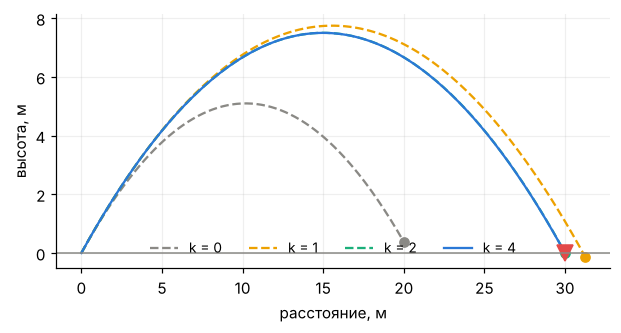

In [4]:
pr = throw_problem()                                          # x = (v1, v2, T), D = 30 м
tk = pr["kkt"]
x0 = np.array([10.0, 10.0, 2.0])                               # старт: мяч пролетает 20 м
lam0 = lam_ls(tk, x0, 2)                                       # J^T lambda ≈ grad f по МНК
hist_t = newton_lagrange(tk, x0, lam0)
x_ip, lam_ip, st = solve_throw_ipopt(pr, x0)
print("lambda(0) =", lam0.round(3), "  в конспекте: (4.903, 5.093)")
print("|F| по итерациям:", ", ".join(f"{h[2]:.2g}" for h in hist_t), "  в конспекте: 10.0, 1.47, 0.026, 6.9e-6, 1.8e-13")
v1, v2, T = hist_t[-1][0]
print(f"наш метод: {len(hist_t) - 1} итерации, IPOPT: {st['iter_count']};  скорость {np.hypot(v1, v2):.2f} м/с, "
      f"угол {np.degrees(np.arctan2(v2, v1)):.1f}°, T = {T:.3f} с, lambda = {hist_t[-1][1].round(3)}")
print("с lambda(0) = 0:", len(newton_lagrange(tk, x0, [0.0, 0.0])) - 1, "итераций")

fig, ax = plt.subplots(figsize=(6.5, 3.0))
for k, c in zip((0, 1, 2), (GRAY, YELLOW, AQUA)):
    X, Y = throw_path(*hist_t[k][0]); ax.plot(X, Y, "--", color=c, label=f"k = {k}"); ax.plot(X[-1], Y[-1], "o", color=c)
X, Y = throw_path(*hist_t[-1][0]); ax.plot(X, Y, color=BLUE, label=f"k = {len(hist_t) - 1}")
ax.plot(30, 0, "v", color=RED, ms=10); ax.axhline(0, color=GRAY, lw=1)
ax.set_xlabel("расстояние, м"); ax.set_ylabel("высота, м"); ax.legend(ncol=4, fontsize=9); plt.show()

**Что видим.** Четыре итерации, столько же, сколько у IPOPT. Ответ — $45^\circ$, $17.16$ м/с, $\lambda^\ast=(4.905,\ 4.905)$. С $\lambda^{(0)}=0$ — на одну итерацию больше. Совпадение лога IPOPT по итерациям — в части (e).

### Демо (b). Матрица ККТ и шаг по частям (разделы 3–4)

**Что проверяем.** Бросок со старта $T=0$; вершину дороги из вопроса залу; три способа §4 дают один шаг.

**Шаг 1. Что делает ячейка.** Печатает $J$ и $g$ задачи «бросок» в старте $v=(10,\ 10)$, $T=0$ и пробует сделать шаг.

In [5]:
_, J0, _, g0 = tk(np.array([10.0, 10.0, 0.0]), np.zeros(2))
print("J =\n", J0, "\ng =", g0, "  ранг J:", np.linalg.matrix_rank(J0))
try:
    newton_lagrange(tk, [10.0, 10.0, 0.0], [0.0, 0.0])
except np.linalg.LinAlgError as err:
    print("шаг не сделан:", err)

J =
 [[ 0.  0. 10.]
 [ 0.  0. 10.]] 
g = [-30.   0.]   ранг J: 1
шаг не сделан: Singular matrix


**Что видим.** Строки $J$ совпадают, ранг 1 — LICQ нарушено. Линеаризованные ограничения требуют $10p_T=30$ и $10p_T=0$ одновременно, и NumPy пишет `Singular matrix`.

**Шаг 2. Что делает ячейка.** Дом в $(0,\ 2)$ над вершиной. Запускает метод из вершины и из $(1,0)$, печатает ответы, расстояния и $Z^\top HZ$.

In [6]:
a_top = np.array([0.0, 2.0])
for x0_ in ([0.0, 0.0], [1.0, 0.0]):
    h = newton_lagrange(road_kkt(a_top), x0_, [0.0])
    x, lam = h[-1][0], h[-1][1]
    J = road_kkt(a_top)(x, lam)[1]; Z = null_space(J)          # направление вдоль дороги
    ZHZ = (Z.T @ road_kkt(a_top)(x, lam)[2] @ Z).item()
    print(f"старт {x0_}: {len(h) - 1} итер., x = {x.round(4)}, lambda = {lam[0]:+.2f}, "
          f"расстояние {np.linalg.norm(x - a_top):.3f}, Z^T H Z = {ZHZ:+.2f}")

старт [0.0, 0.0]: 1 итер., x = [0. 0.], lambda = -2.00, расстояние 2.000, Z^T H Z = -3.00
старт [1.0, 0.0]: 4 итер., x = [1.2247 1.5   ], lambda = -0.50, расстояние 1.323, Z^T H Z = +0.86


**Что видим.** Из вершины метод не уходит: одна итерация, $\lambda=-2$, расстояние $2$. Там $Z^\top HZ=-3<0$ — это не минимум. Из $(1,0)$ метод приходит в ближайшую точку $(1.22,\ 1.5)$: расстояние $1.32$, $Z^\top HZ>0$.

**Шаг 3. Что делает ячейка.** Функция `kkt_matrix` собирает матрицу ККТ $K$. Функция `three_ways` находит шаг тремя способами §4: всей матрицей $K$, способом null-space и способом range-space. Запускаем её в задаче «дорога» в $(1,0)$ и в задаче «бросок» в старте с $\lambda^{(0)}$ по МНК.

In [7]:
def kkt_matrix(kkt, x, lam):
    """Матрица ККТ [[H, -J^T], [J, 0]] в точке (x, lam)."""
    _, J, H, _ = kkt(x, lam)
    m = J.shape[0]
    return np.block([[H, -J.T], [J, np.zeros((m, m))]])

def three_ways(kkt, x, lam):
    """Шаг (p, lambda+) тремя способами: вся K, null-space, range-space."""
    gf, J, H, g = kkt(x, lam)
    n, m = H.shape[0], J.shape[0]
    s = np.linalg.solve(kkt_matrix(kkt, x, lam), -np.concatenate([gf - J.T @ lam, g]))
    full = (s[:n], lam + s[n:])                                   # вся матрица (n + m) x (n + m)
    pN = -J.T @ np.linalg.solve(J @ J.T, g)                       # к ограничению: J pN = -g
    Z = null_space(J)                                             # базис касательного пространства
    u = np.linalg.solve(Z.T @ H @ Z, -Z.T @ (gf + H @ pN))        # система (n - m) x (n - m)
    p = pN + Z @ u
    null = (p, np.linalg.lstsq(J.T, H @ p + gf, rcond=None)[0])   # множители после шага
    lp = np.linalg.solve(J @ np.linalg.solve(H, J.T), J @ np.linalg.solve(H, gf) - g)   # система m x m
    rng = (np.linalg.solve(H, J.T @ lp - gf), lp)
    return full, null, rng, pN, Z @ u

rk = road_kkt(A_ROAD)                                         # задача «дорога»
for name, kkt, x, lam in (("дорога", rk, np.array([1.0, 0.0]), np.zeros(1)), ("бросок", tk, x0, lam0)):
    full, null, rng, pN, Zu = three_ways(kkt, x, lam)
    print(f"{name}: p = {full[0].round(4)}, lambda+ = {full[1].round(4)}")
    print(f"   расхождение: null-space {np.abs(full[0] - null[0]).max():.0e}, range-space {np.abs(full[0] - rng[0]).max():.0e}")
    if name == "дорога":
        print(f"   p_N = {pN.round(3)}, Zu = {Zu.round(3)}   (в конспекте: (-0.4, 0.2) и (0.6, 1.2))")

дорога: p = [0.2 1.4], lambda+ = [0.4]
   расхождение: null-space 2e-16, range-space 0e+00
   p_N = [-0.4  0.2], Zu = [0.6 1.2]   (в конспекте: (-0.4, 0.2) и (0.6, 1.2))
бросок: p = [2.3831 2.3275 0.5234], lambda+ = [4.9084 4.8309]
   расхождение: null-space 1e-14, range-space 2e-12


**Что видим.** В задаче «дорога» $p_N=(-0.4,\ 0.2)$, $Zu=(0.6,\ 1.2)$ и $\lambda^+=0.4$ — как в §4. В задаче «бросок» оба способа совпадают с полной матрицей. У range-space ошибка округления в сто раз больше: $H$ броска почти вырождена (упражнение 9.3).

### Демо (c). Обобщённый Гаусс–Ньютон (раздел 5)

**Что проверяем.** В задаче «дорога» ошибка за шаг умножается на $q=-2\lambda^\ast/(1+4x_1^{\ast2})$; в задаче «бросок» метод не сходится.

**Что делает ячейка.** Для трёх домов запускает Ньютон–Лагранж и обобщённый Гаусс–Ньютон (`road_ggn_kkt`: в матрице $I$ вместо $H$) из $(1,0)$. Печатает $q$ по формуле, измеренное отношение соседних ошибок и число итераций.

In [8]:
for a in ((1.5, 2.0), (2.0, 1.0), (0.0, 0.3)):
    a = np.array(a)
    hn = newton_lagrange(road_kkt(a), [1.0, 0.0], [0.0])
    hg = newton_lagrange(road_ggn_kkt(a), [1.0, 0.0], [0.0], maxit=500)
    xs, ls = hn[-1][0], hn[-1][1][0]
    q = -2 * ls / (1 + 4 * xs[0]**2)                              # множитель ошибки по формуле §5
    e = np.array([np.linalg.norm(t[0] - xs) for t in hg])         # ошибка Гаусса–Ньютона
    print(f"дом {a}: q = {q:+.4f}, измерено |e(k+1)/e(k)| = {e[4] / e[3]:.4f}; "
          f"итераций: Гаусс–Ньютон {len(hg) - 1}, Ньютон–Лагранж {len(hn) - 1}")
print("в конспекте: 6/4, 11/4, 43/6")

ggn_throw = lambda x, lam: (*tk(x, lam)[:2], np.diag([1.0, 1.0, 0.0]), tk(x, lam)[3])   # J_r^T J_r броска
h = newton_lagrange(ggn_throw, x0, lam0, maxit=30)
print("бросок, Гаусс–Ньютон: |F| на итерациях 26–30:", [f"{t[2]:.2f}" for t in h[-5:]])

дом [1.5 2. ]: q = -0.0059, измерено |e(k+1)/e(k)| = 0.0055; итераций: Гаусс–Ньютон 6, Ньютон–Лагранж 4
дом [2. 1.]: q = -0.1113, измерено |e(k+1)/e(k)| = 0.1127; итераций: Гаусс–Ньютон 11, Ньютон–Лагранж 4
дом [0.  0.3]: q = +0.6000, измерено |e(k+1)/e(k)| = 0.5894; итераций: Гаусс–Ньютон 43, Ньютон–Лагранж 6
в конспекте: 6/4, 11/4, 43/6
бросок, Гаусс–Ньютон: |F| на итерациях 26–30: ['5.49', '5.76', '5.49', '5.76', '5.49']


**Что видим.** Измеренное отношение ошибок совпадает с $|q|$ (у первого дома ошибка падает так быстро, что отношение видно хуже). В задаче «бросок» невязка качается около 5 и не падает: $\lambda^\ast=4.905$ велико.